In [5]:
import torch
import transformers
print("Name: Jai Dayanand")
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)

Name: Jai Dayanand
torch: 2.15.0+cpu
transformers: 5.22.2


# CSE 256 PA2 — Part 3: Dissecting Pythia
**Jai Dayanand**

The following analyses use `EleutherAI/pythia-160m-deduped` at checkpoints throughout pretraining. Each experiment reports its numerical outputs, figures, and interpretations alongside the code that produced them. Evaluation uses the pretrained Pythia tokenizer and float32 model weights. Reproducing the experiments requires the speech test data and access to the checkpoint weights.


In [6]:
from pathlib import Path
import gc, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display
from transformers import AutoTokenizer, GPTNeoXForCausalLM

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_NAME = "EleutherAI/pythia-160m-deduped"
FINAL = "step143000"
CONTEXT = 128
READOUT_CHUNK = 32

# Find the data whether Jupyter starts in PA2_code or its parent.
candidates = [Path("speechesdataset/test_LM_obama.txt"),
              Path("PA2_code/speechesdataset/test_LM_obama.txt")]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Open this notebook from PA2_code, or edit DATA_PATH.")
OUT = DATA_PATH.parent.parent / "outputs" / "part3"
OUT.mkdir(parents=True, exist_ok=True)
text = DATA_PATH.read_text(encoding="utf-8")
tok = AutoTokenizer.from_pretrained(MODEL_NAME, revision=FINAL)
all_ids = tok(text, add_special_tokens=False, return_tensors="pt",
              verbose=False).input_ids[0]
assert len(all_ids) > 1
print("Device:", DEVICE, "| Python:", platform.python_version())
print("Data:", DATA_PATH.resolve())
print("Pythia tokens:", len(all_ids), "| predicted transitions:", len(all_ids)-1)
print("Output folder:", OUT.resolve())
print("Evaluation: whole file; 128 prediction positions per window;")
print("adjacent windows share one boundary token; context resets each window.")

manifest = dict(model=MODEL_NAME, context=CONTEXT, seed=SEED,
                torch=str(torch.__version__), transformers=transformers.__version__,
                data_sha256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
                token_count=len(all_ids), dtype="float32")
(OUT / "run_config.json").write_text(json.dumps(manifest, indent=2))

Device: cpu | Python: 3.12.7
Data: C:\Users\Jai Dayanand\Downloads\UCSD_Assignments\CSE256\CSE256_PA2_FA26\PA2_code\speechesdataset\test_LM_obama.txt
Pythia tokens: 6017 | predicted transitions: 6016
Output folder: C:\Users\Jai Dayanand\Downloads\UCSD_Assignments\CSE256\CSE256_PA2_FA26\PA2_code\outputs\part3
Evaluation: whole file; 128 prediction positions per window;
adjacent windows share one boundary token; context resets each window.


262

## 3.1 Reading Pythia
Read [Biderman et al. (2023)](https://proceedings.mlr.press/v202/biderman23a/biderman23a.pdf), especially Sections 2.6 and 3.1--3.3.

### 3.1.1 Why checkpoints?
The **memorization study (Section 3.2)** depends most on Pythia's checkpoint and fixed-data-order design: the authors examine the occurrence of memorized sequences over training, using the known training-data sequence to study their dependence on location and time. For a study that could **mostly** be carried out with final models, I would choose a *static version* of the **term-frequency/few-shot-accuracy study (Section 3.3)**: one could compare final-model task performance against pretraining term frequencies. However, doing so would **not** reproduce the paper's central temporal finding, namely that the relationship emerges partway through pretraining. The gender-bias intervention (Section 3.1) also requires access to earlier training states to resume training on modified data, so the complete experiment cannot be reduced to only final-model evaluation.

### 3.1.2 Deduplicated versus original data
Section 2.6 reports no clear language-modeling performance benefit from deduplication in this controlled suite. This is a finding about these experiments, rather than a universal claim that deduplication is ineffective.

Reference: Biderman et al., *Pythia: A Suite for Analyzing Large Language Models Across Training and Scaling*, ICML 2023, Sections 2.6 and 3.2–3.3.

## Shared analysis functions
The logit lens applies the checkpoint's own final layer norm and output projection to intermediate residual states. The final returned hidden state is checked against the actual logits to avoid applying final layer norm twice. Layer 0 is explicitly read from the embedding weights.

The evaluation predicts **every adjacent token pair in the full file exactly once**. At window boundaries context resets. All checkpoints and transplants use this identical protocol; these subword-token metrics are not directly comparable with Part 2's word-level perplexities.

In [7]:
def release_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_model(revision):
    print("Loading", revision, flush=True)
    m = GPTNeoXForCausalLM.from_pretrained(
        MODEL_NAME, revision=revision,
        torch_dtype=torch.float32, attn_implementation="eager",
    ).to(DEVICE).eval()
    m.requires_grad_(False)
    assert m.config.num_hidden_layers == 12
    assert m.config.hidden_size == 768
    assert m.config.num_attention_heads == 12
    assert next(m.parameters()).dtype == torch.float32
    return m


def output_head(m):
    return m.get_output_embeddings()


def windows():
    for start in range(0, len(all_ids)-1, CONTEXT):
        # Every window has one extra token for shifted targets.
        w = all_ids[start:start+CONTEXT+1].unsqueeze(0).to(DEVICE)
        yield w


@torch.inference_mode()
def verify_hidden_convention(m):
    x = all_ids[:12].unsqueeze(0).to(DEVICE)
    out = m(x, output_hidden_states=True, use_cache=False)
    assert len(out.hidden_states) == 13
    direct = output_head(m)(out.hidden_states[-1])
    normalized = output_head(m)(m.gpt_neox.final_layer_norm(out.hidden_states[-1]))
    direct_error = (direct-out.logits).abs().max().item()
    normalized_error = (normalized-out.logits).abs().max().item()
    already_normalized = torch.allclose(direct, out.logits, atol=1e-5, rtol=1e-5)
    if not already_normalized:
        assert torch.allclose(normalized, out.logits, atol=1e-5, rtol=1e-5)
    embedded = m.get_input_embeddings()(x)
    assert torch.allclose(embedded, out.hidden_states[0], atol=1e-5, rtol=1e-5)
    print("Final hidden state already normalized:", already_normalized)
    print("Logit max errors — direct:", direct_error,
          "after another LN:", normalized_error)
    return already_normalized


def lens_logits(m, hidden, layer, already_normalized):
    if layer == 12 and already_normalized:
        return output_head(m)(hidden)
    return output_head(m)(m.gpt_neox.final_layer_norm(hidden))


@torch.inference_mode()
def lens_accuracy(m, already_normalized):
    correct = np.zeros(13, dtype=np.int64)
    count = 0
    for w in windows():
        out = m(w[:, :-1], output_hidden_states=True, use_cache=False)
        targets = w[:, 1:]
        for layer, hidden in enumerate(out.hidden_states):
            if layer == 0:
                hidden = m.get_input_embeddings()(w[:, :-1])
            for start in range(0, targets.shape[1], READOUT_CHUNK):
                stop = start + READOUT_CHUNK
                logits = lens_logits(m, hidden[:, start:stop], layer,
                                     already_normalized)
                correct[layer] += (logits.argmax(-1) == targets[:, start:stop]).sum().item()
        count += targets.numel()
    assert count == len(all_ids)-1
    return correct / count, correct, count


@torch.inference_mode()
def corpus_loss(m):
    total, count = 0.0, 0
    for w in windows():
        logits = m(w[:, :-1], use_cache=False).logits
        targets = w[:, 1:]
        for start in range(0, targets.shape[1], READOUT_CHUNK):
            stop = start + READOUT_CHUNK
            total += torch.nn.functional.cross_entropy(
                logits[:, start:stop].reshape(-1, logits.shape[-1]),
                targets[:, start:stop].reshape(-1), reduction="sum").item()
        count += targets.numel()
    assert count == len(all_ids)-1
    return total/count


def token_label(token_id):
    return tok.decode([int(token_id)]).replace(" ", "▁").replace("\n", "\\n")


@torch.inference_mode()
def lens_grid(m, sentence, already_normalized, filename):
    ids = tok(sentence, add_special_tokens=False, return_tensors="pt").input_ids.to(DEVICE)
    assert 2 <= ids.shape[1] <= m.config.max_position_embeddings
    out = m(ids[:, :-1], output_hidden_states=True, use_cache=False)
    targets = ids[:, 1:]
    probabilities, predictions = [], []
    for layer, hidden in enumerate(out.hidden_states):
        if layer == 0:
            hidden = m.get_input_embeddings()(ids[:, :-1])
        logits = lens_logits(m, hidden, layer, already_normalized)
        probs = logits.softmax(-1)
        probabilities.append(probs.gather(-1, targets.unsqueeze(-1)).squeeze().reshape(-1).cpu().numpy())
        predictions.append(logits.argmax(-1)[0].cpu().numpy())
    probabilities = np.stack(probabilities)
    predictions = np.stack(predictions)
    fig, ax = plt.subplots(figsize=(max(10, targets.numel()*0.8), 8))
    im = ax.imshow(probabilities, origin="lower", aspect="auto", vmin=0, vmax=1, cmap="Blues")
    for layer in range(13):
        for pos in range(targets.numel()):
            ax.text(pos, layer, token_label(predictions[layer, pos]),
                    ha="center", va="center", fontsize=7,
                    color="white" if probabilities[layer, pos] > .5 else "black")
    ax.set_xticks(range(targets.numel()))
    ax.set_xticklabels([token_label(i) for i in ids[0, :-1]], rotation=60, ha="right")
    ax.set_yticks(range(13))
    ax.set_ylabel("Layer (0 = embedding)")
    ax.set_xlabel("Input token; each cell predicts the following token")
    ax.set_title(sentence + "\nCell text: top prediction; shade: true next-token probability")
    fig.colorbar(im, ax=ax, label="Probability of true next token")
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=180, bbox_inches="tight")
    plt.show()
    print("Subword tokens:", ids.numel())
    print("True next tokens:", [token_label(i) for i in targets[0]])
    np.savez(OUT / filename.replace(".png", ".npz"), probabilities=probabilities,
             predictions=predictions, ids=ids.cpu().numpy())

## 3.2.1 Watch a prediction form
Final checkpoint: `step143000`. Each grid excludes the last input position because the supplied sentence provides no next-token target there.

Loading step143000


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 574.48it/s]


Final hidden state already normalized: True
Logit max errors — direct: 0.0 after another LN: 7.51715087890625


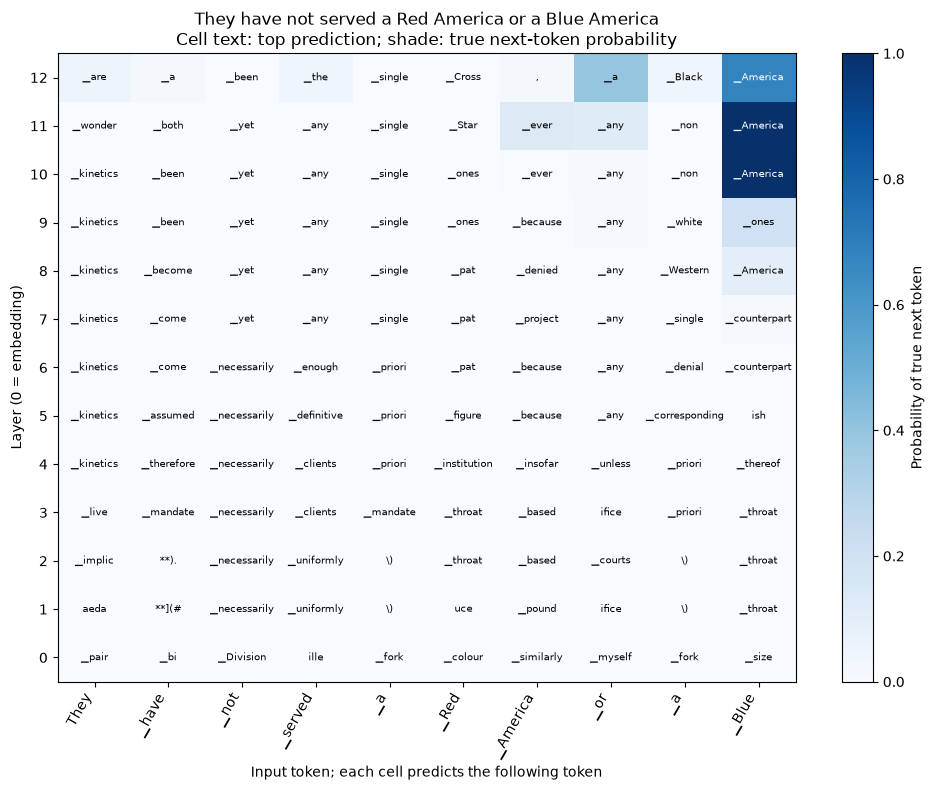

Subword tokens: 11
True next tokens: ['▁have', '▁not', '▁served', '▁a', '▁Red', '▁America', '▁or', '▁a', '▁Blue', '▁America']


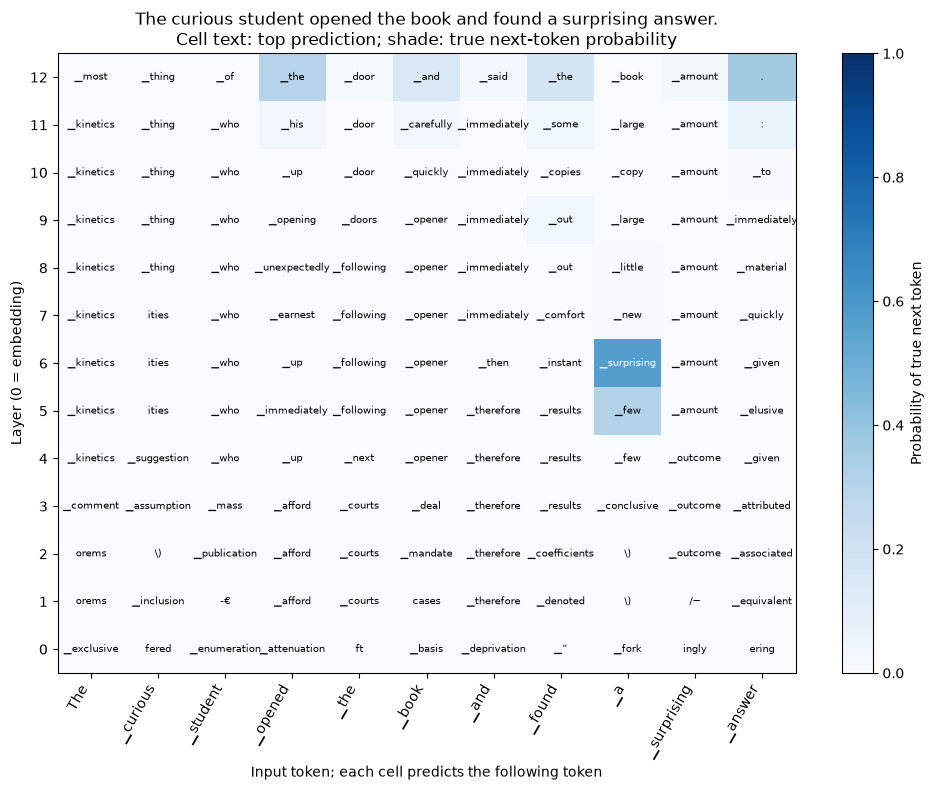

Subword tokens: 12
True next tokens: ['▁curious', '▁student', '▁opened', '▁the', '▁book', '▁and', '▁found', '▁a', '▁surprising', '▁answer', '.']


In [8]:
model = load_model(FINAL)
final_normalized = verify_hidden_convention(model)
sentence_obama = "They have not served a Red America or a Blue America"
# Original sentence used for logit-lens analysis.
sentence_own = "The curious student opened the book and found a surprising answer."
lens_grid(model, sentence_obama, final_normalized, "grid_obama.png")
lens_grid(model, sentence_own, final_normalized, "grid_original.png")

Layer 0: 1/6016 = 0.0001662234 (0.016622%)
Layer 6: 283/6016 = 0.0470412234 (4.704122%)
Layer 12: 2086/6016 = 0.3467420213 (34.674202%)


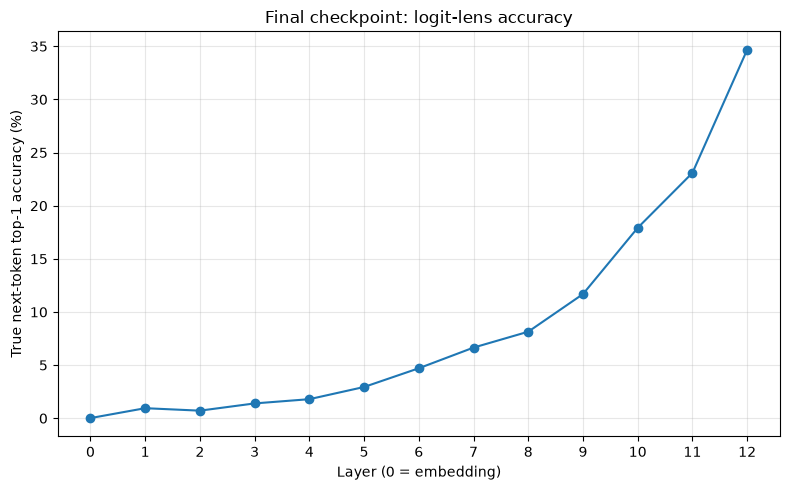

In [9]:
final_accuracy, final_correct, denominator = lens_accuracy(model, final_normalized)
for layer in [0, 6, 12]:
    print(f"Layer {layer}: {final_correct[layer]}/{denominator} = "
          f"{final_accuracy[layer]:.10f} ({100*final_accuracy[layer]:.6f}%)")
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(13), 100*final_accuracy, marker="o")
ax.set(xticks=range(13), xlabel="Layer (0 = embedding)",
       ylabel="True next-token top-1 accuracy (%)", title="Final checkpoint: logit-lens accuracy")
ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(OUT / "final_accuracy.png", dpi=180); plt.show()
pd.DataFrame({"layer": range(13), "correct": final_correct,
              "count": denominator, "accuracy": final_accuracy}).to_csv(OUT / "final_accuracy.csv", index=False)
del model
release_memory()

### 3.2.1 Interpretation — final-checkpoint logit lens

The two layer-by-position grids above show the top next-token predictions for the specified Obama passage and for the original sentence, *“The curious student opened the book and found a surprising answer.”* Each cell's color reflects the probability assigned to the true next token, not the probability assigned to the displayed top prediction. The grid makes it possible to compare the embedding-only predictions with intermediate and final predictions at each position.

Across all 6,016 next-token pairs in `test_LM_obama.txt`, the embedding-only readout (layer 0) gets **1/6,016 = 0.016622%** correct, layer 6 gets **283/6,016 = 4.704122%**, and the final layer 12 gets **2,086/6,016 = 34.674202%**. This demonstrates substantially better predictive accuracy at the end of the network than at the embedding or midpoint. Improvement is **not strictly monotonic**: accuracy falls from 0.9475% at layer 1 to 0.7148% at layer 2, then rises through the later layers. These are empirical properties of the plotted readouts rather than evidence that each layer independently performs next-word classification.


## 3.2.2 Across training
The same full-file token pairs and context boundaries are used at all four checkpoints. Each checkpoint uses its own final layer norm and unembedding.

Loading step512


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 456.70it/s]


Final hidden state already normalized: True
Logit max errors — direct: 0.0 after another LN: 0.35659098625183105
step512 layer 0/6/12: [0.00049867 0.11486037 0.20329122]
Loading step1000


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 440.27it/s]


Final hidden state already normalized: True
Logit max errors — direct: 0.0 after another LN: 0.806854248046875
step1000 layer 0/6/12: [0.00033245 0.15043218 0.24318484]
Loading step8000


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 502.62it/s]


Final hidden state already normalized: True
Logit max errors — direct: 0.0 after another LN: 5.333597183227539
step8000 layer 0/6/12: [0.00049867 0.14943484 0.33560505]


,layer,step143000,step512,step1000,step8000
0,0,0.000166,0.000499,0.000332,0.000499
1,1,0.009475,0.017453,0.019282,0.031915
2,2,0.007148,0.070811,0.056017,0.040725
3,3,0.013963,0.115858,0.079455,0.073305
4,4,0.017952,0.112035,0.112367,0.086935
5,5,0.029422,0.112699,0.145113,0.117354
6,6,0.047041,0.114860,0.150432,0.149435
7,7,0.066489,0.113032,0.159408,0.181516
8,8,0.081449,0.126496,0.166223,0.201297
9,9,0.116855,0.158577,0.187999,0.232547


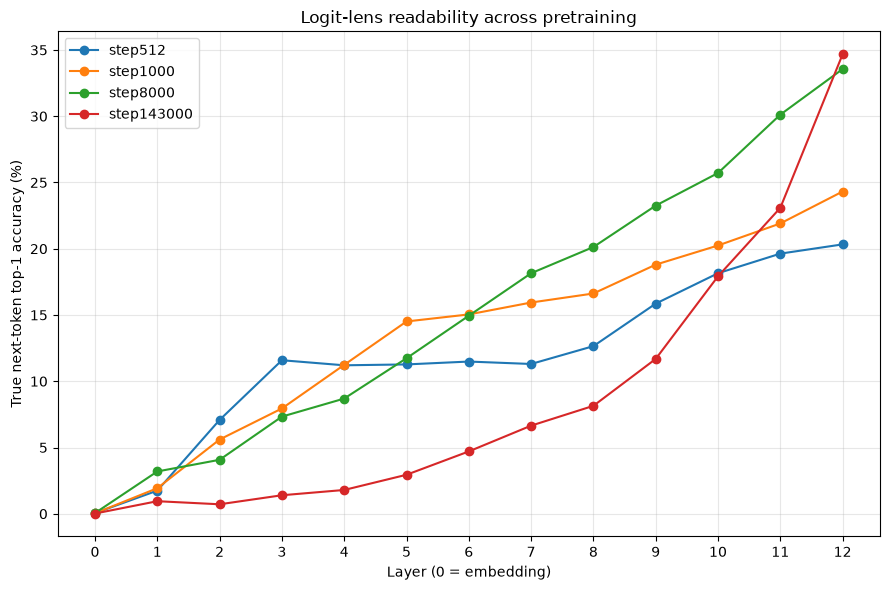

In [10]:
curves = {FINAL: final_accuracy.copy()}
for revision in ["step512", "step1000", "step8000"]:
    model = load_model(revision)
    convention = verify_hidden_convention(model)
    accuracy, correct, count = lens_accuracy(model, convention)
    curves[revision] = accuracy
    print(revision, "layer 0/6/12:", accuracy[[0, 6, 12]])
    del model
    release_memory()

curve_table = pd.DataFrame({"layer": range(13), **curves})
display(curve_table)
curve_table.to_csv(OUT / "checkpoint_accuracy.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 6))
for revision in ["step512", "step1000", "step8000", FINAL]:
    ax.plot(range(13), 100*curves[revision], marker="o", label=revision)
ax.set(xticks=range(13), xlabel="Layer (0 = embedding)",
       ylabel="True next-token top-1 accuracy (%)", title="Logit-lens readability across pretraining")
ax.legend(); ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(OUT / "checkpoint_accuracy.png", dpi=180); plt.show()

### 3.2.2 Interpretation — changes across pretraining

The later checkpoint has a substantially better **final** next-token readout: layer-12 accuracy increases from **20.3291%** at step512 to **24.3185%** at step1000, **33.5605%** at step8000, and **34.6742%** at step143000. Intermediate-layer *untuned logit-lens* readability, however, does not improve monotonically as training progresses. At layer 6 the accuracies are **11.4860%**, **15.0432%**, **14.9435%**, and only **4.7041%**, respectively. At layer 8 they are **12.6496%**, **16.6223%**, **20.1297%**, and **8.1449%**. Thus the final model predicts better at the output while its intermediate states are harder to decode using the *final-layer readout*.

One plausible interpretation is that intermediate representations increasingly differ from the coordinate system or feature distribution expected by the checkpoint's final normalization and unembedding. A raw logit lens applies this final readout to states it was not trained to interpret directly. Consequently, low middle-layer lens accuracy **does not establish that next-token information has been lost**. Layer-specific readouts such as the tuned lens are designed to separate readout misalignment from information that is genuinely unavailable. The differences across these checkpoints are not uniform: for example, step1000 is slightly better than step8000 at layer 6, while step8000 is better at layer 8.

Optional context: [Belrose et al. (2023), *Eliciting Latent Predictions from Transformers with the Tuned Lens*](https://arxiv.org/abs/2303.08112).


## 3.3 Transplanting layers across time
Recipient: intact `step143000`. Donors: `step0`, `step1000`, `step8000`, `step32000`.

Components: token embedding, each of the 12 complete Transformer blocks, and output unembedding. The recipient's final layer norm is held fixed. Blocks are numbered **1–12** here (Hugging Face indices 0–11). The embedding and unembedding are separate, untied components. The metric is the change in mean next-token cross-entropy, in nats/token.

Each transplant is restored in a `finally` block and checked tensor by tensor. The baseline is rechecked after each donor. The full corpus is evaluated for every pair.

In [11]:
def components(m):
    return {"embedding": m.get_input_embeddings(),
            **{f"block_{i+1:02d}": block for i, block in enumerate(m.gpt_neox.layers)},
            "unembedding": output_head(m)}


def snapshot(module):
    return {key: value.detach().cpu().clone()
            for key, value in module.state_dict().items()}


model = load_model(FINAL)
assert model.get_input_embeddings().weight.data_ptr() != output_head(model).weight.data_ptr(), \
    "This experiment assumes untied input/output weights."
baseline = corpus_loss(model)
print(f"Intact final model baseline: {baseline:.10f} nats/token")
recipient_components = components(model)
component_names = list(recipient_components)
donors = ["step0", "step1000", "step8000", "step32000"]
deltas = pd.DataFrame(index=component_names, columns=donors, dtype=float)
losses = deltas.copy()

for revision in donors:
    donor = load_model(revision)
    donor_components = components(donor)
    for name, recipient_module in recipient_components.items():
        original = snapshot(recipient_module)
        try:
            recipient_module.load_state_dict(donor_components[name].state_dict(), strict=True)
            transplanted_loss = corpus_loss(model)
            losses.loc[name, revision] = transplanted_loss
            deltas.loc[name, revision] = transplanted_loss - baseline
            print(f"{revision:>10} | {name:>12} | loss {transplanted_loss:.8f} | "
                  f"delta {transplanted_loss-baseline:+.8f}", flush=True)
        finally:
            recipient_module.load_state_dict(original, strict=True)
            for key, value in recipient_module.state_dict().items():
                assert torch.equal(value.detach().cpu(), original[key]), f"Restore failed: {name}/{key}"
        del original
        # Save progress, but reruns recompute rather than silently reusing old cells.
        deltas.to_csv(OUT / "transplant_deltas.csv")
        losses.to_csv(OUT / "transplant_losses.csv")
    restored_loss = corpus_loss(model)
    assert abs(restored_loss-baseline) < 1e-5, "Recipient baseline changed."
    print("Restored baseline check PASSED:", restored_loss)
    del donor_components, donor
    release_memory()

print("Baseline loss (nats/token):", baseline)
display(deltas)
(OUT / "baseline.json").write_text(json.dumps({"loss_nats_per_token": baseline}, indent=2))

Loading step143000


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 567.64it/s]


Intact final model baseline: 3.4617656152 nats/token
Loading step0


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1112.27it/s]


     step0 |    embedding | loss 8.57390565 | delta +5.11214004
     step0 |     block_01 | loss 8.65458387 | delta +5.19281825
     step0 |     block_02 | loss 4.23498340 | delta +0.77321778
     step0 |     block_03 | loss 4.46389110 | delta +1.00212548
     step0 |     block_04 | loss 4.31632560 | delta +0.85455998
     step0 |     block_05 | loss 3.94973858 | delta +0.48797296
     step0 |     block_06 | loss 3.88774278 | delta +0.42597717
     step0 |     block_07 | loss 3.82442032 | delta +0.36265470
     step0 |     block_08 | loss 3.78909697 | delta +0.32733136
     step0 |     block_09 | loss 3.83226879 | delta +0.37050318
     step0 |     block_10 | loss 3.90834231 | delta +0.44657670
     step0 |     block_11 | loss 4.24886684 | delta +0.78710123
     step0 |     block_12 | loss 8.32575322 | delta +4.86398760
     step0 |  unembedding | loss 20.03662766 | delta +16.57486204
Restored baseline check PASSED: 3.4617656152299108
Loading step1000


Loading weights: 100%|██████████| 148/148 [00:00<00:00, 880.98it/s]


... (3 outputs left out)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 1173.78it/s]


 step32000 |    embedding | loss 3.60539660 | delta +0.14363099
 step32000 |     block_01 | loss 4.39039314 | delta +0.92862753
 step32000 |     block_02 | loss 4.26604455 | delta +0.80427893
 step32000 |     block_03 | loss 4.07385172 | delta +0.61208611
 step32000 |     block_04 | loss 4.38346221 | delta +0.92169660
 step32000 |     block_05 | loss 4.05550865 | delta +0.59374303
 step32000 |     block_06 | loss 3.95176445 | delta +0.48999883
 step32000 |     block_07 | loss 3.90958794 | delta +0.44782232
 step32000 |     block_08 | loss 4.35557126 | delta +0.89380565
 step32000 |     block_09 | loss 4.13749046 | delta +0.67572484
 step32000 |     block_10 | loss 4.55420382 | delta +1.09243820
 step32000 |     block_11 | loss 5.35267118 | delta +1.89090556
 step32000 |     block_12 | loss 8.94665640 | delta +5.48489078
 step32000 |  unembedding | loss 83.96371306 | delta +80.50194744
Restored baseline check PASSED: 3.4617656152299108
Baseline loss (nats/token): 3.4617656152299108


,step0,step1000,step8000,step32000
embedding,5.112140,2.671381,0.562388,0.143631
block_01,5.192818,4.891606,1.077945,0.928628
block_02,0.773218,0.783622,1.009787,0.804279
block_03,1.002125,0.874845,0.838251,0.612086
block_04,0.854560,0.908579,1.451258,0.921697
block_05,0.487973,0.526555,3.257457,0.593743
block_06,0.425977,0.463071,0.902111,0.489999
block_07,0.362655,0.323579,0.536737,0.447822
block_08,0.327331,0.318752,0.809686,0.893806
block_09,0.370503,0.376567,0.798080,0.675725


47

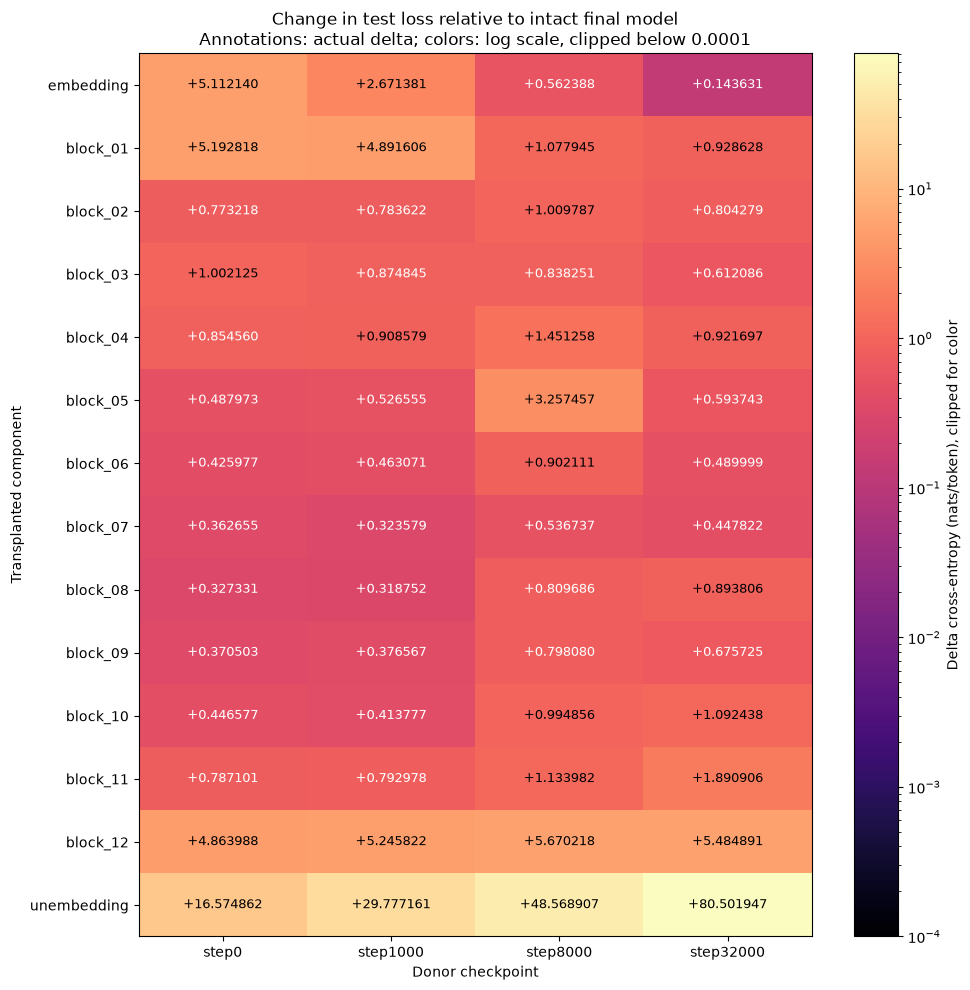

Random-donor damage, smallest to largest:


,delta_loss
block_08,0.327331
block_07,0.362655
block_09,0.370503
block_06,0.425977
block_10,0.446577
block_05,0.487973
block_02,0.773218
block_11,0.787101
block_04,0.854560
block_03,1.002125


Adjacent donor pairs where a later donor is more damaging:


,component,earlier,later,earlier_delta,later_delta
0,block_02,step0,step1000,0.773218,0.783622
1,block_02,step1000,step8000,0.783622,1.009787
2,block_04,step0,step1000,0.854560,0.908579
3,block_04,step1000,step8000,0.908579,1.451258
4,block_05,step0,step1000,0.487973,0.526555
5,block_05,step1000,step8000,0.526555,3.257457
6,block_06,step0,step1000,0.425977,0.463071
7,block_06,step1000,step8000,0.463071,0.902111
8,block_07,step1000,step8000,0.323579,0.536737
9,block_08,step1000,step8000,0.318752,0.809686


In [12]:
values = deltas.to_numpy(dtype=float)
assert np.isfinite(values).all()
floor = 1e-4
ceiling = max(float(values.max()), floor*10)
# Only the displayed colors are clipped; annotations and CSV retain real deltas.
colors = np.clip(values, floor, ceiling)
fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(colors, aspect="auto", cmap="magma",
               norm=LogNorm(vmin=floor, vmax=ceiling))
ax.set_xticks(range(len(donors)))
ax.set_xticklabels(donors)
ax.set_yticks(range(len(component_names)))
ax.set_yticklabels(component_names)
for row in range(len(component_names)):
    for col in range(len(donors)):
        rgba = im.cmap(im.norm(colors[row, col]))
        luminance = .2126*rgba[0] + .7152*rgba[1] + .0722*rgba[2]
        ax.text(col, row, f"{values[row, col]:+.6f}", ha="center", va="center",
                fontsize=9, color="black" if luminance > .5 else "white")
ax.set_xlabel("Donor checkpoint")
ax.set_ylabel("Transplanted component")
ax.set_title("Change in test loss relative to intact final model\n"
             "Annotations: actual delta; colors: log scale, clipped below 0.0001")
fig.colorbar(im, ax=ax, label="Delta cross-entropy (nats/token), clipped for color")
fig.tight_layout(); fig.savefig(OUT / "transplant_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

print("Random-donor damage, smallest to largest:")
display(deltas["step0"].sort_values().to_frame("delta_loss"))
print("Adjacent donor pairs where a later donor is more damaging:")
violations = []
for name in component_names:
    for earlier, later in zip(donors[:-1], donors[1:]):
        if deltas.loc[name, later] > deltas.loc[name, earlier] + 1e-6:
            violations.append(dict(component=name, earlier=earlier, later=later,
                                   earlier_delta=deltas.loc[name, earlier],
                                   later_delta=deltas.loc[name, later]))
if violations:
    display(pd.DataFrame(violations))
else:
    print("None under the stated numerical tolerance.")
del recipient_components, model
release_memory()

### 3.3 Interpretation — which older components can be transplanted?

The intact step143000 recipient has a baseline mean next-token cross-entropy of **3.461766 nats/token**. Replacing one component with step0 weights causes comparatively little damage for several middle blocks: block 8 increases loss by only **0.327331**, block 7 by **0.362655**, and block 9 by **0.370503 nats/token**. By comparison, the **unembedding** is especially difficult to replace (**+16.574862**), followed by block 1 (**+5.192818**), the token embedding (**+5.112140**), and block 12 (**+4.863988**). Here “little damage” is relative to the very large losses observed for the most critical components; even a +0.33 increase is measurable.

**A later donor does not always hurt less.** The unembedding transplant becomes dramatically worse from step0 (**+16.574862**) to step32000 (**+80.501947**). Block 5 gives another striking counterexample: step1000 causes **+0.526555**, but the later step8000 donor causes **+3.257457**, before the step32000 donor drops to **+0.593743**. Block 12 likewise grows from **+4.863988** at step0 to **+5.670218** at step8000. These numbers rule out a simple monotonic compatibility story. A plausible explanation is that an older component's representations and the fixed final recipient's surrounding components can become *less compatible* at particular intermediate training stages, even while the donor model itself improves. The experiment establishes the incompatibility effects; it does not isolate their mechanistic cause.

Each heatmap cell contains the measured change in corpus test loss, and only the color scale is clipped for visualization. All transplants were evaluated against the same intact final-model baseline, with component weights restored and checked after each replacement.
